# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
%pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

Note: you may need to restart the kernel to use updated packages.


In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: False
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/qd/70glcmfn6jlb3qbk1clvmfzc0000gn/T/ipykernel_16184/1236436484.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/var/folders/qd/70glcmfn6jlb3qbk1clvmfzc0000gn/T/ipykernel_16184/3322223012.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer="counts",
    batch_key="donor_id",
    span=0.5
)
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [5]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    use_rep="X_pca",
    transformer="sklearn"
)

sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

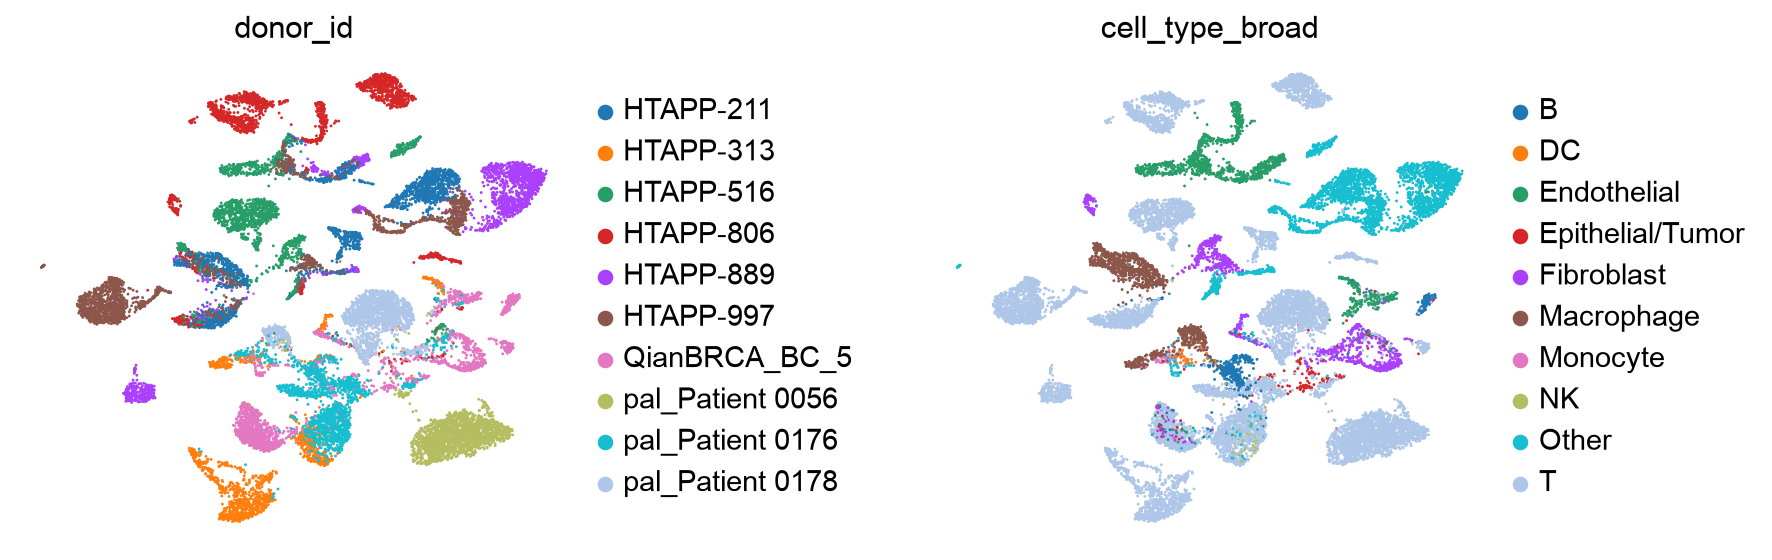

In [6]:
sc.pl.embedding(
    adata,
    basis="umap_unint",
    color=["donor_id", "cell_type_broad"],
    wspace=0.5,
    frameon=False
)

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

*Your answer here.* The unintegrated UMAP shows clustering by both donor and cell type, with several clusters dominated by individual donors. While major cell types are distinguishable, the donor-specific separation suggests that batch effects may contribute to the observed variation.

In [7]:
# Fix conflicting index names
adata.var.index.name = None

if adata.raw is not None:
    adata.raw.var.index.name = None

# Confirm raw counts are available for scVI
print("Counts layer:", "counts" in adata.layers)
print("Shape:", adata.shape)

# Save preprocessed data
adata.write_h5ad("breast_cancer_preprocessed.h5ad")

print("Saved successfully!")

Counts layer: True
Shape: (18388, 2000)
Saved successfully!


In [8]:
from pathlib import Path

file = Path("breast_cancer_preprocessed.h5ad").resolve()
print(file)
print(f"File size: {file.stat().st_size / 1024**2:.1f} MB")

/Users/heojiin/Downloads/breast_cancer_preprocessed.h5ad
File size: 584.9 MB


## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [9]:
# ============================================================
# 1.4 · Integrate with scVI (GPU step)
# ============================================================

# Original scVI training code
# Training was completed separately on Northeastern Explorer
# using an NVIDIA Tesla P100 GPU (200 epochs, 30 latent dimensions).
# The code below is commented out to avoid retraining on the local CPU.

# import scvi
# scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
# vae = scvi.model.SCVI(adata, n_latent=30)
# vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
# adata.obsm["X_scVI"] = vae.get_latent_representation()
# sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI", transformer="sklearn")
# sc.tl.umap(adata)
# adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
# print("scVI done")

**scVI Training and Reproducibility Note**

scVI integration was performed separately on Northeastern University's Explorer HPC cluster using an NVIDIA Tesla P100 GPU. The model was trained for 200 epochs with 30 latent dimensions, using `donor_id` as the batch variable and raw counts as input.

The trained latent representation and UMAP coordinates were saved in `breast_cancer_scvi.h5ad` and loaded into the local environment for downstream analysis. The original training code is retained above as comments to document the workflow and avoid unnecessary retraining.

During GPU execution, the neighborhood graph was computed using `transformer="sklearn"` to address a Scanpy/SciPy compatibility issue.

In [10]:
# 1.4 · Load scVI integration results (trained on Explorer GPU)

import scanpy as sc
from pathlib import Path

# Load the saved AnnData object
data_path = Path.home() / "Downloads" / "breast_cancer_scvi.h5ad"
adata = sc.read_h5ad(data_path)

# Verify that scVI results are available
assert "X_scVI" in adata.obsm, "scVI latent representation missing"
assert "X_umap_scvi" in adata.obsm, "scVI UMAP missing"

print("scVI results loaded successfully!")
print("Shape:", adata.shape)
print("scVI latent:", adata.obsm["X_scVI"].shape)
print("scVI UMAP:", adata.obsm["X_umap_scvi"].shape)

scVI results loaded successfully!
Shape: (18388, 2000)
scVI latent: (18388, 30)
scVI UMAP: (18388, 2)


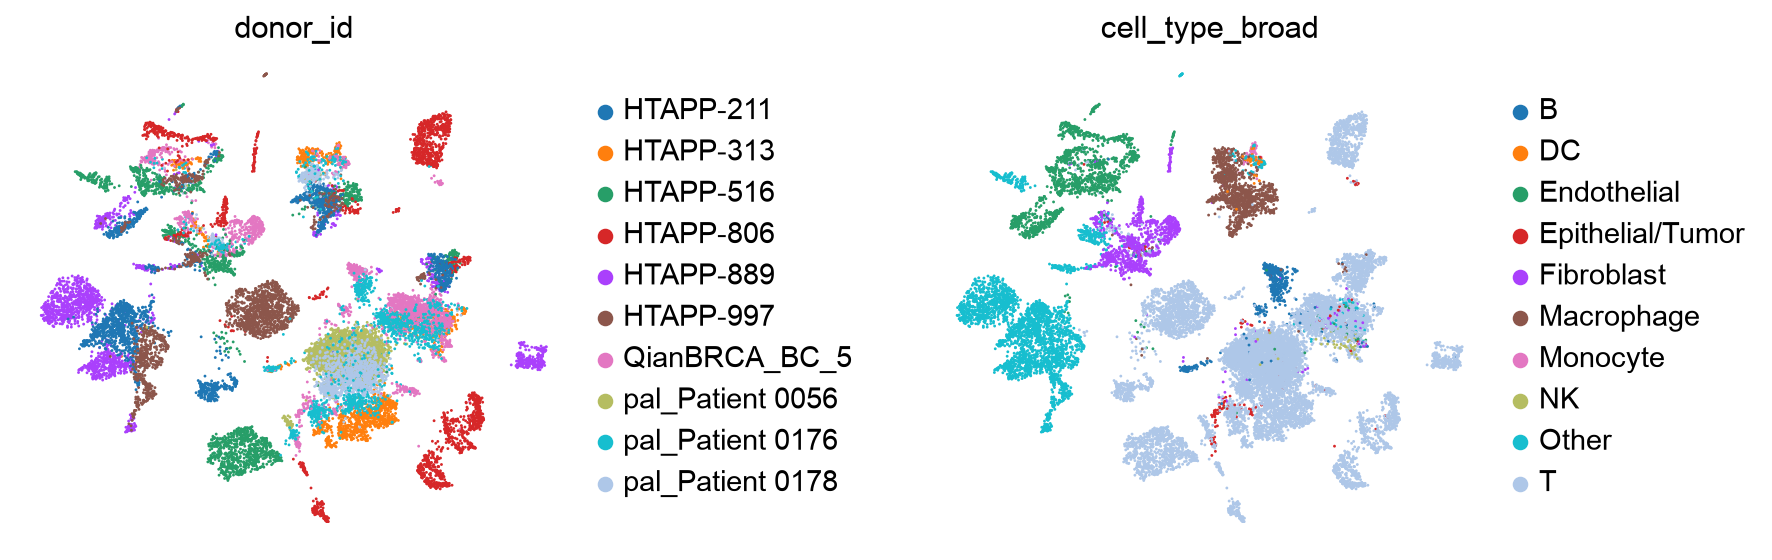

In [11]:
sc.pl.embedding(
    adata,
    basis="umap_scvi",
    color=["donor_id", "cell_type_broad"],
    wspace=0.5,
    frameon=False
)

## 1.5 · Harmony, a fair baseline  *(provided)*

In [12]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-18 20:31:36,879 - harmonypy - INFO - Running Harmony
2026-11-18 20:31:36,880 - harmonypy - INFO -   Parameters:
2026-11-18 20:31:36,880 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-18 20:31:36,880 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-18 20:31:36,880 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-18 20:31:36,880 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-18 20:31:36,881 - harmonypy - INFO -     nclust: 100
2026-11-18 20:31:36,881 - harmonypy - INFO -     block_size: 0.05
2026-11-18 20:31:36,881 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-18 20:31:36,881 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-11-18 20:31:36,881 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-18 20:31:36,881 - harmonypy - INFO -     verbose: True
2026-11-18 20:31:36,881 - harmonypy - INFO -     random_state: 0
2026-11-18 20:31:36,882 - harmonypy - INFO -   Data: 50 PCs × 18388 cells
2026-11-18 20:31:36,882 - 

Harmony done


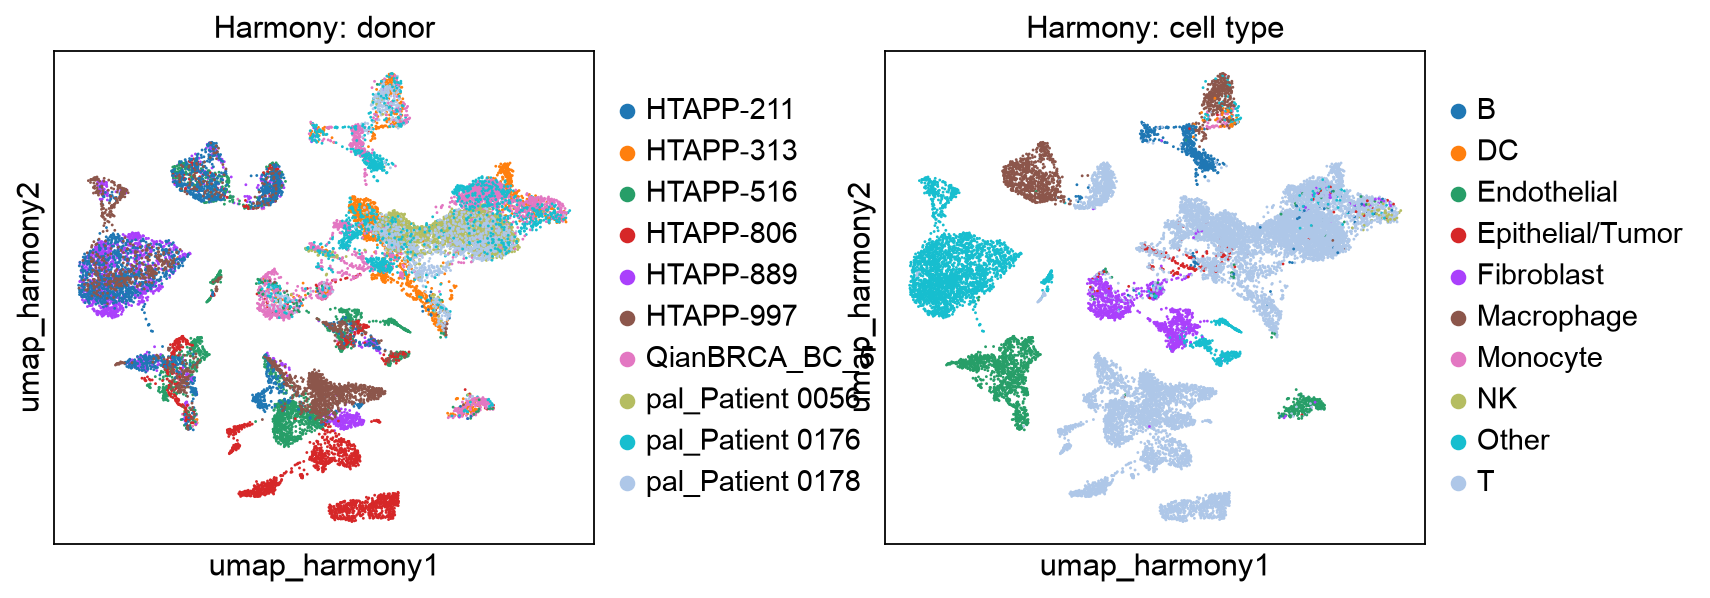

In [ ]:
# Visualize Harmony-integrated UMAP
import scanpy as sc

sc.pp.neighbors(
    adata,
    n_neighbors=15,
    use_rep="X_pca_harmony",
    transformer="sklearn"
)
sc.tl.umap(adata)

adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()

sc.pl.embedding(
    adata,
    basis="umap_harmony",
    color=["donor_id", "cell_type_broad"],
    wspace=0.8,
    title=["Harmony: donor", "Harmony: cell type"]
)

## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [14]:
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

rng = np.random.default_rng(0)

# Randomly sample up to 5,000 cells
idx = rng.choice(
    adata.n_obs,
    size=min(5000, adata.n_obs),
    replace=False
)

reps = {
    "No integration": "X_pca",
    "Harmony": "X_pca_harmony",
    "scVI": "X_scVI"
}

results = []

for name, key in reps.items():
    emb = adata.obsm[key][idx]

    batch = silhouette_score(
        emb,
        adata.obs["donor_id"].values[idx]
    )

    bio = silhouette_score(
        emb,
        adata.obs["cell_type_broad"].values[idx]
    )

    results.append({
        "Method": name,
        "Batch silhouette": round(batch, 3),
        "Biology silhouette": round(bio, 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Method,Batch silhouette,Biology silhouette
0,No integration,0.091,-0.009
1,Harmony,-0.082,0.026
2,scVI,-0.060,0.031


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

*Your answer here.* I would choose scVI because it achieved the highest biology silhouette score (0.031) while also reducing donor-associated separation compared with no integration. However, Harmony showed a lower batch silhouette score (-0.082 vs. -0.060), suggesting better donor mixing. The difference in biology preservation was very small (0.031 vs. 0.026), so scVI does not clearly outperform Harmony despite its higher computational cost. Harmony would also be a reasonable choice, especially if computational efficiency is a priority.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

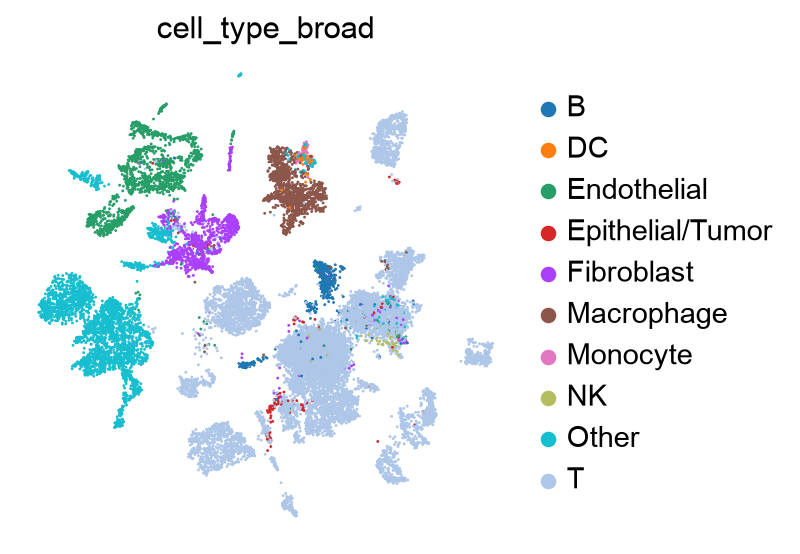

Available markers: ['CD3D', 'MS4A1', 'CD14', 'EPCAM', 'PECAM1', 'COL1A1']


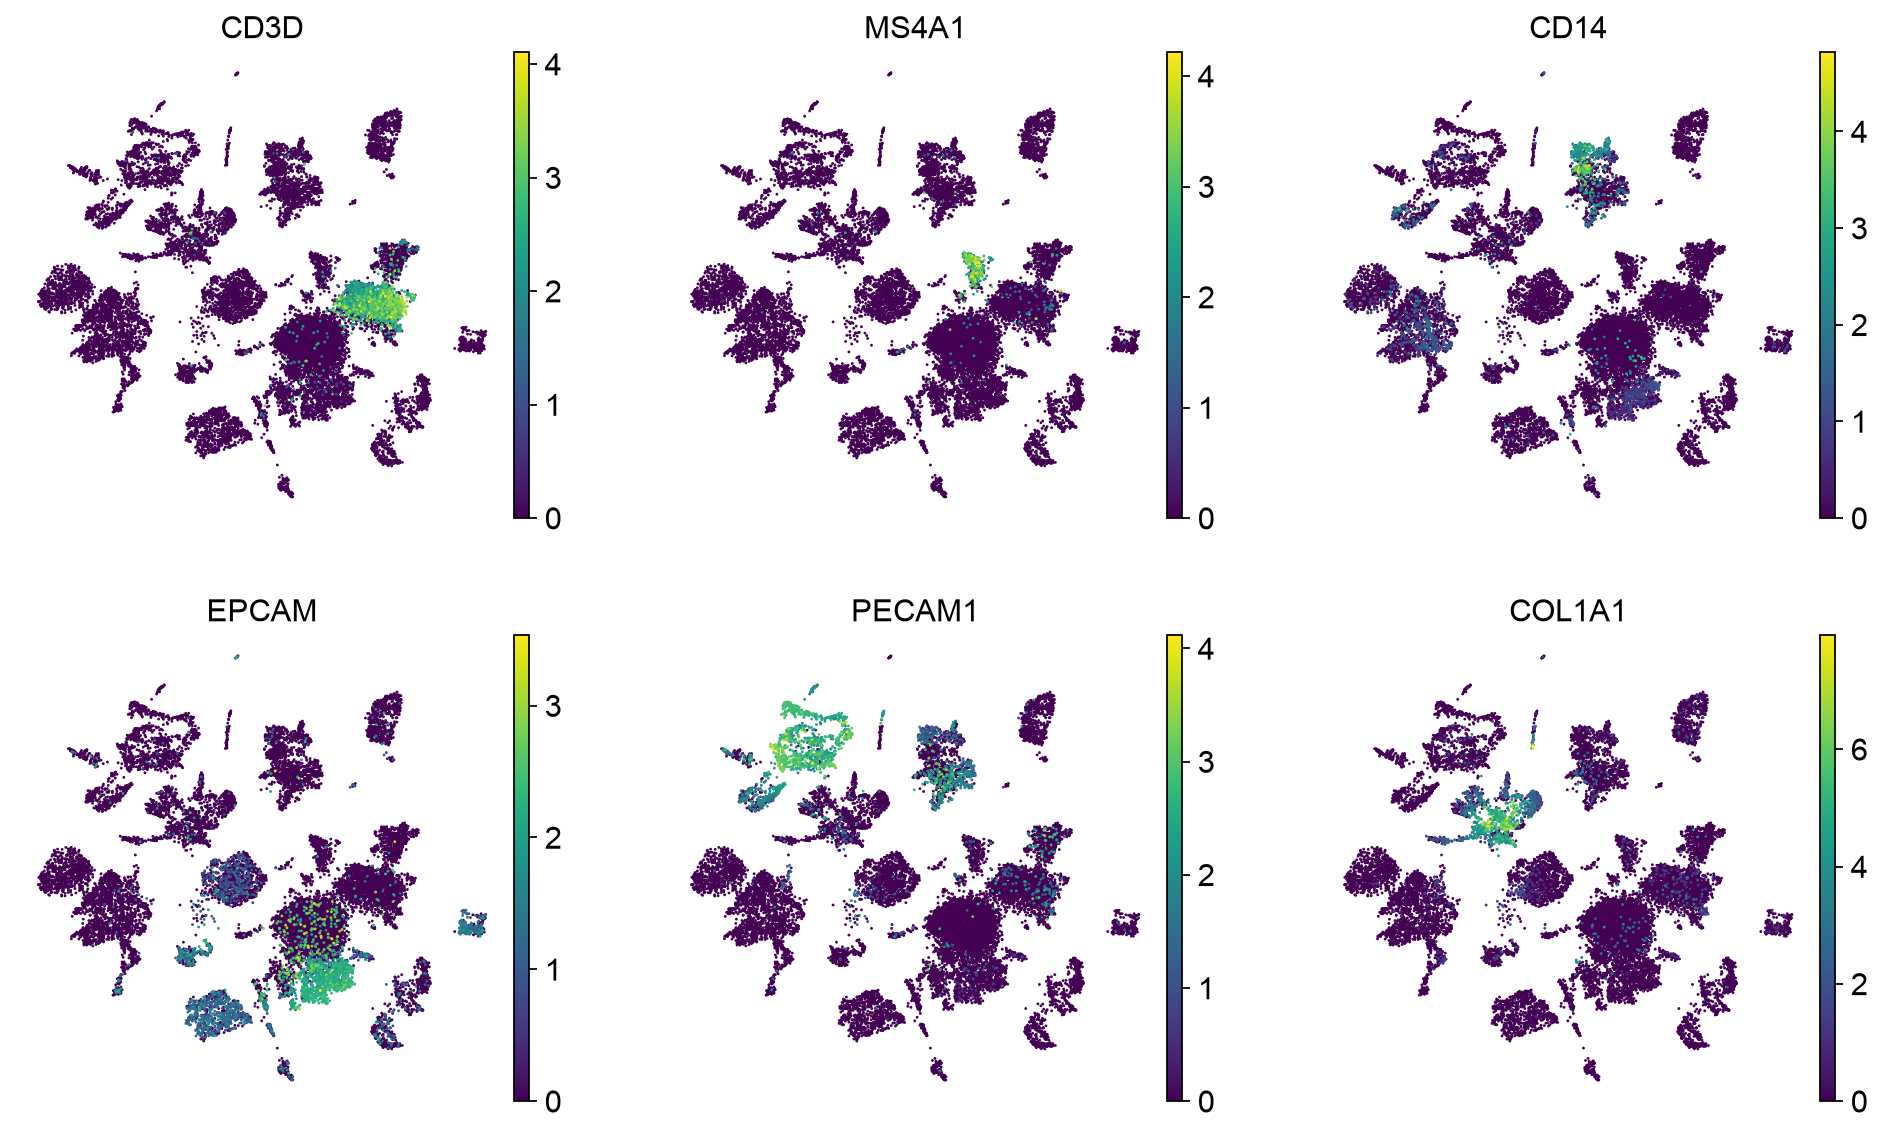

In [15]:
# Cell-type annotation
sc.pl.embedding(
    adata,
    basis="umap_scvi",
    color="cell_type_broad",
    frameon=False
)

# Canonical marker genes
markers = [
    g for g in ["CD3D", "MS4A1", "CD14", "EPCAM", "PECAM1", "COL1A1"]
    if adata.raw is not None and g in adata.raw.var_names
]

print("Available markers:", markers)

sc.pl.embedding(
    adata,
    basis="umap_scvi",
    color=markers,
    use_raw=True,
    ncols=3,
    frameon=False,
    cmap="viridis"
)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

Target available: True


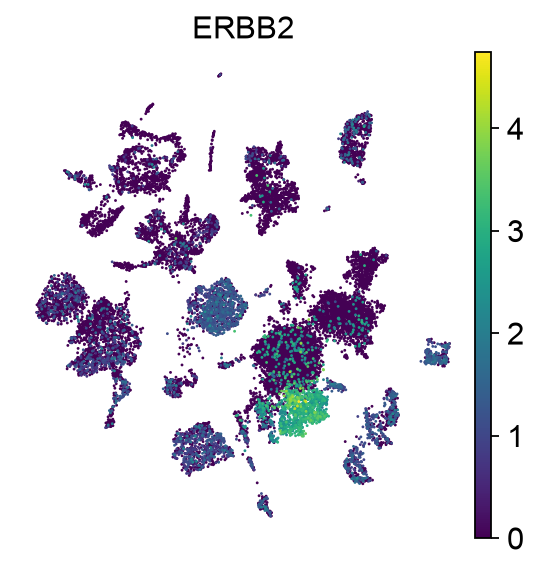

In [16]:
TARGET = "ERBB2"

# Check whether the target gene is available
print("Target available:", TARGET in adata.raw.var_names)

# Plot target expression on scVI UMAP
sc.pl.embedding(
    adata,
    basis="umap_scvi",
    color=TARGET,
    use_raw=True,
    frameon=False,
    cmap="viridis"
)

**TODO (interpretation):** Which cell type(s) express your target? 

*Your answer here.* ERBB2 expression is most prominent in a subset of epithelial/tumor-associated cells, particularly in the lower central region of the scVI UMAP. Lower levels of expression are also observed across other clusters. This suggests heterogeneous ERBB2 expression rather than uniform expression across the cell population.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [17]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/var/folders/qd/70glcmfn6jlb3qbk1clvmfzc0000gn/T/ipykernel_16184/520941202.py:1: FutureWarning: Use `squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scanpy/datasets/_datasets.py:555: FutureWarning: Use `squidpy.read.visium` instead.
  return read_visium(sample_dir, source_image_path=source_image_path)


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (3798, 36601)


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 2.2 · Pipeline and clustering  *(provided)*

In [18]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/qd/70glcmfn6jlb3qbk1clvmfzc0000gn/T/ipykernel_16184/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

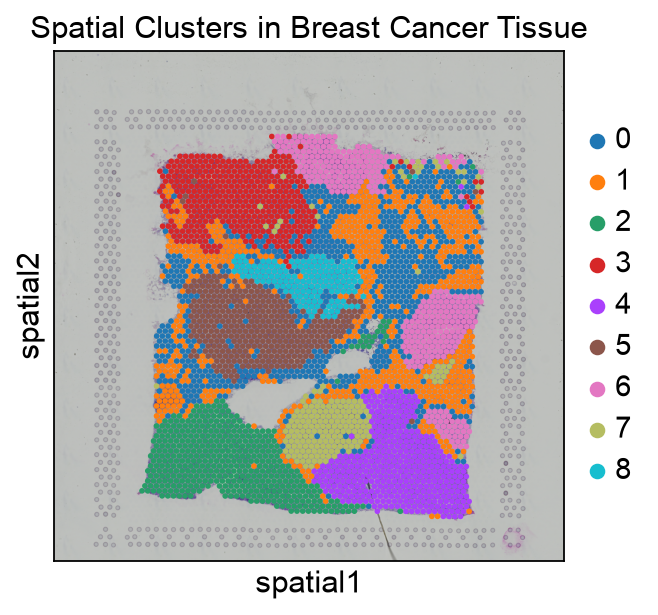

In [19]:
sq.pl.spatial_scatter(
    spatial,
    color="cluster",
    size=1.5,
    title="Spatial Clusters in Breast Cancer Tissue"
)

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

*Your answer here.* The spatial clusters form distinct regions across the tissue, suggesting that they reflect underlying tissue architecture. Several clusters occupy large, continuous areas, while others are concentrated in smaller regions or along cluster boundaries. These patterns may correspond to different tumor, stromal, or immune-associated compartments. However, marker gene expression and histological information are needed to confirm the identity of each domain.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [20]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/qd/70glcmfn6jlb3qbk1clvmfzc0000gn/T/ipykernel_16184/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I
MGP     0.868504
MALAT1  0.762550
CRISP3  0.726334
CPB1    0.711023
IGHG3   0.703817
IGLC2   0.700306
IGKC    0.680696
ALB     0.667866


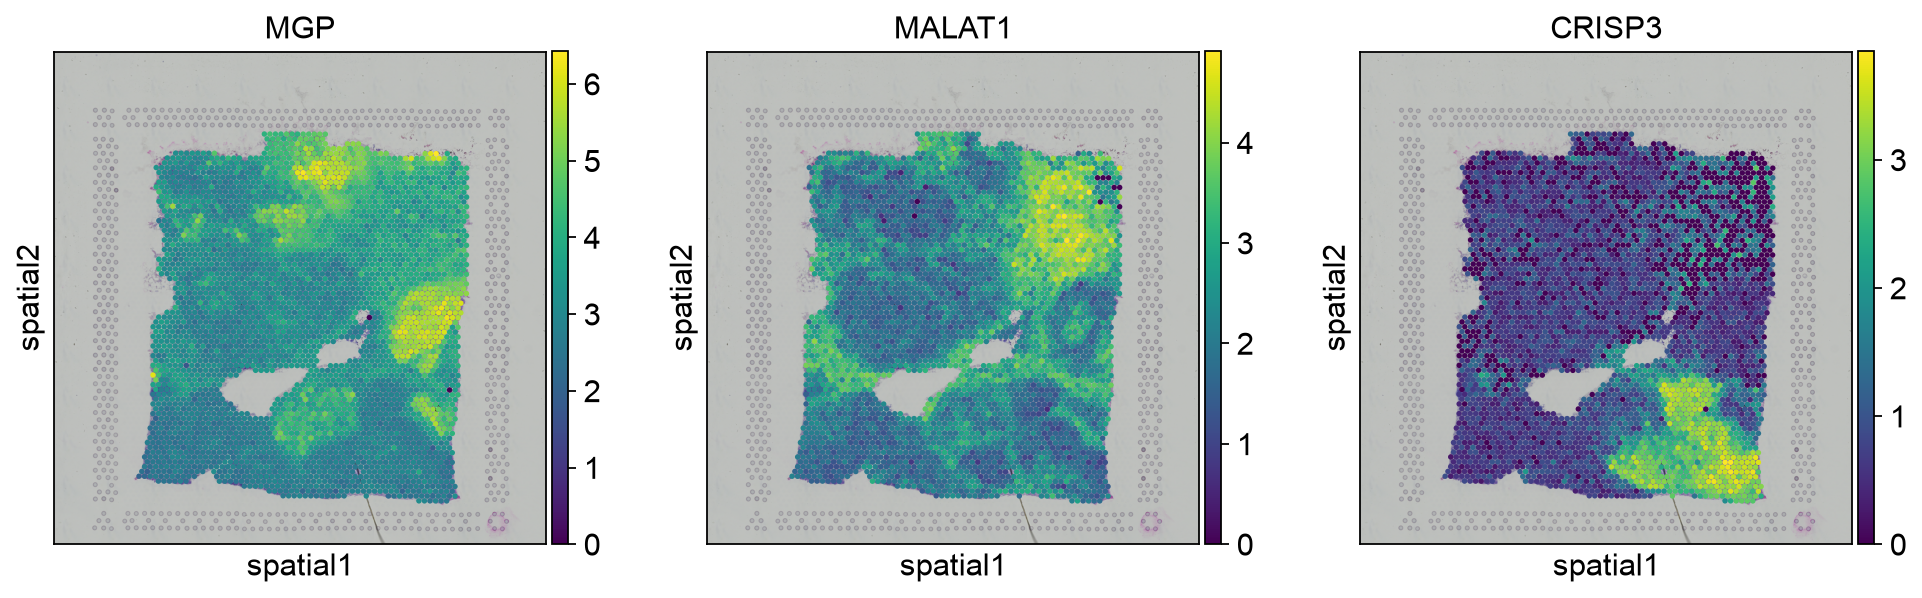

In [21]:
# Compute Moran's I for spatial autocorrelation
sq.gr.spatial_autocorr(
    spatial,
    mode="moran"
)

# Display top 8 spatially variable genes
top = spatial.uns["moranI"].head(8)
print(top[["I"]])

# Plot top 3 genes on the tissue
top_genes = top.head(3).index.tolist()

sq.pl.spatial_scatter(
    spatial,
    color=top_genes,
    size=1.5
)

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


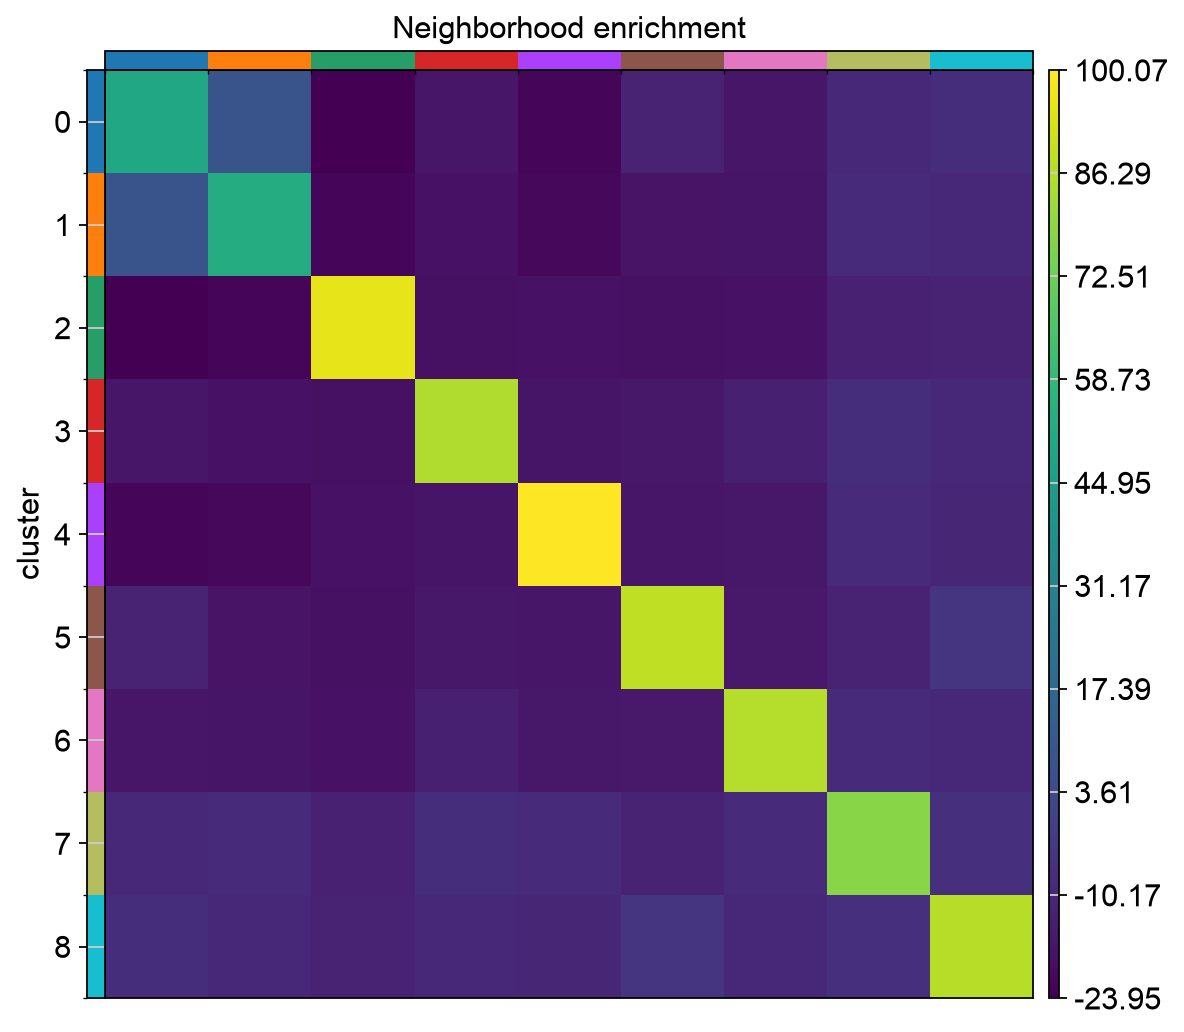

In [22]:
# Compute neighborhood enrichment
sq.gr.nhood_enrichment(
    spatial,
    cluster_key="cluster"
)

# Plot neighborhood enrichment heatmap
sq.pl.nhood_enrichment(
    spatial,
    cluster_key="cluster",
    figsize=(7, 6)
)



**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

*Your answer here.* The neighborhood enrichment heatmap shows strong enrichment within each cluster, indicating that spots from the same spatial domain tend to group together. Among different clusters, clusters 0 and 1 show the clearest positive enrichment, suggesting that they share a spatial interface more often than expected by chance. Most other cluster pairs show weak or negative enrichment. However, a tumor–immune boundary cannot be confirmed from this analysis alone because the biological identities of the clusters have not yet been established.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

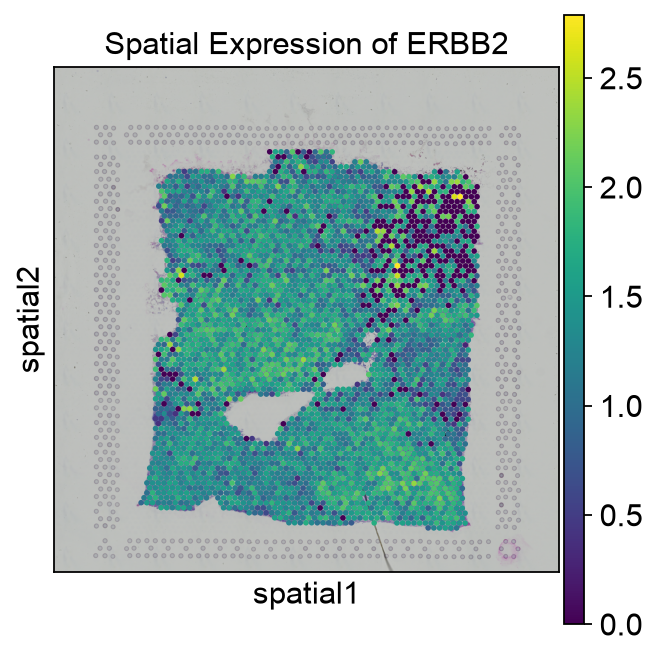

In [ ]:
TARGET = "ERBB2"

if spatial.raw is not None and TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(
        spatial,
        color=TARGET,
        size=1.5,
        title="Spatial Expression of ERBB2"
    )
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")


**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

*Your answer here.* ERBB2 expression is distributed across much of the tissue, with relatively higher expression in the central and left-middle regions. This pattern may be consistent with tumor-associated areas rather than a distinct immune niche or invasive margin. However, the expression is not restricted to a single spatial domain, and the tumor core cannot be definitively identified without additional histological or marker-based annotation.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.

**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

*Your answer here.* I would choose scVI because it achieved the highest biology silhouette score (0.031) while also reducing donor-associated separation compared with no integration. However, Harmony showed a lower batch silhouette score (-0.082 vs. -0.060), suggesting better donor mixing. The difference in biology preservation was very small (0.031 vs. 0.026), so scVI does not clearly outperform Harmony despite its higher computational cost. Harmony would also be a reasonable choice, especially if computational efficiency is a priority.